## Name: Tushar Zhade
USC ID: 3922421673,
Github Username: tusharz7

## Question 1 a)

In [1]:
# Prompt: "Load the APS training and test CSVs, skipping the license header and reading "na" as missing, then show the shapes and class counts."
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path("../Homework 6 Data")

# Each CSV starts with a 20 line license header, and missing values are stored as "na"
aps_train = pd.read_csv(data_dir / "aps_failure_training_set.csv", skiprows=20, na_values="na")
aps_test = pd.read_csv(data_dir / "aps_failure_test_set.csv", skiprows=20, na_values="na")

target_name = "class"
aps_features = [c for c in aps_train.columns if c != target_name]

print(f"Training set: {aps_train.shape}, test set: {aps_test.shape}")
print(f"Features: {len(aps_features)}, all numeric: {all(pd.api.types.is_numeric_dtype(aps_train[c]) for c in aps_features)}")
print(f"Training classes: {aps_train[target_name].value_counts().to_dict()}")
print(f"Test classes: {aps_test[target_name].value_counts().to_dict()}")
aps_train.head()


Training set: (60000, 171), test set: (16000, 171)
Features: 170, all numeric: True
Training classes: {'neg': 59000, 'pos': 1000}
Test classes: {'neg': 15625, 'pos': 375}


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


## Question 1 b) i

One of them is using median imputed values for NA values, and another is using the mean. I will be using mean imputed values for missingness. 

In [2]:
# Prompt: "Fill the missing values with mean imputation fit on the training set only, apply it to both sets, and encode the class as 0/1."
from sklearn.impute import SimpleImputer

# Mean imputation. The means come from the training set only, so no test data leaks in
imputer = SimpleImputer(strategy="mean").fit(aps_train[aps_features])

X_train = pd.DataFrame(imputer.transform(aps_train[aps_features]), columns=aps_features)
X_test = pd.DataFrame(imputer.transform(aps_test[aps_features]), columns=aps_features)
y_train = (aps_train[target_name] == "pos").astype(int)  # neg = 0, pos = 1
y_test = (aps_test[target_name] == "pos").astype(int)


## Question 1 b) ii

In [3]:
# Prompt: "Compute the coefficient of variation (sample std / mean) for each of the 170 features and sort it from highest to lowest."
# Coefficient of variation s / m for each feature on the imputed training set (ddof=1 gives the sample std)
feature_cv = (X_train.std(ddof=1) / X_train.mean()).sort_values(ascending=False)


## Question 1 b) iii

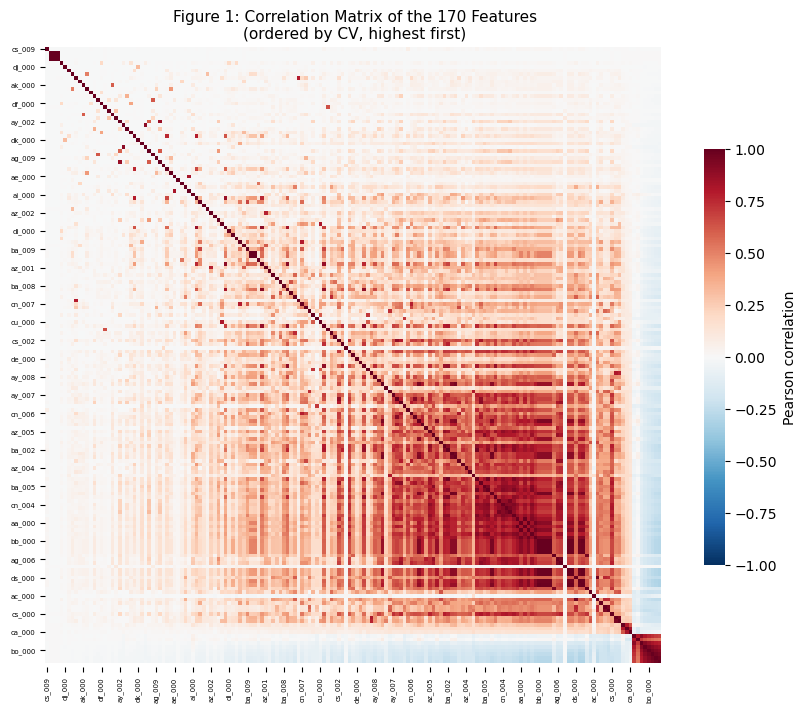

In [4]:
# Prompt: "Plot a seaborn heatmap of the correlation matrix for all 170 features, ordered by CV."
import seaborn as sns

# Correlation matrix of the imputed training features, ordered from highest to lowest CV
cv_order = feature_cv.index
feature_corr = X_train[cv_order].corr()

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    feature_corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=5,  # label every 5th feature so the names stay readable
    yticklabels=5,
    cbar_kws={"shrink": 0.6, "label": "Pearson correlation"},
    ax=ax,
)
ax.tick_params(labelsize=5)
ax.set_title("Figure 1: Correlation Matrix of the 170 Features\n(ordered by CV, highest first)", fontsize=11)
plt.show()


## Question 1 b) iv

In [5]:
# Prompt: "Pick the floor(sqrt(170)) features with the highest CV and log-transform them for plotting."
# floor(sqrt(170)) = 13 features with the highest CV
n_top = int(np.floor(np.sqrt(len(aps_features))))
top_cv_features = list(feature_cv.index[:n_top])

# The features are heavily right-skewed, so plot log(1 + x) to make the spread visible
plot_data = np.log1p(X_train[top_cv_features])
plot_data["class"] = aps_train[target_name]
plot_data = plot_data.sort_values("class")  # draw pos after neg so the rare class sits on top

print(f"Top {n_top} CV features: {top_cv_features}")


Top 13 CV features: ['cs_009', 'cf_000', 'co_000', 'ad_000', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'az_009', 'ak_000', 'au_000', 'ch_000']


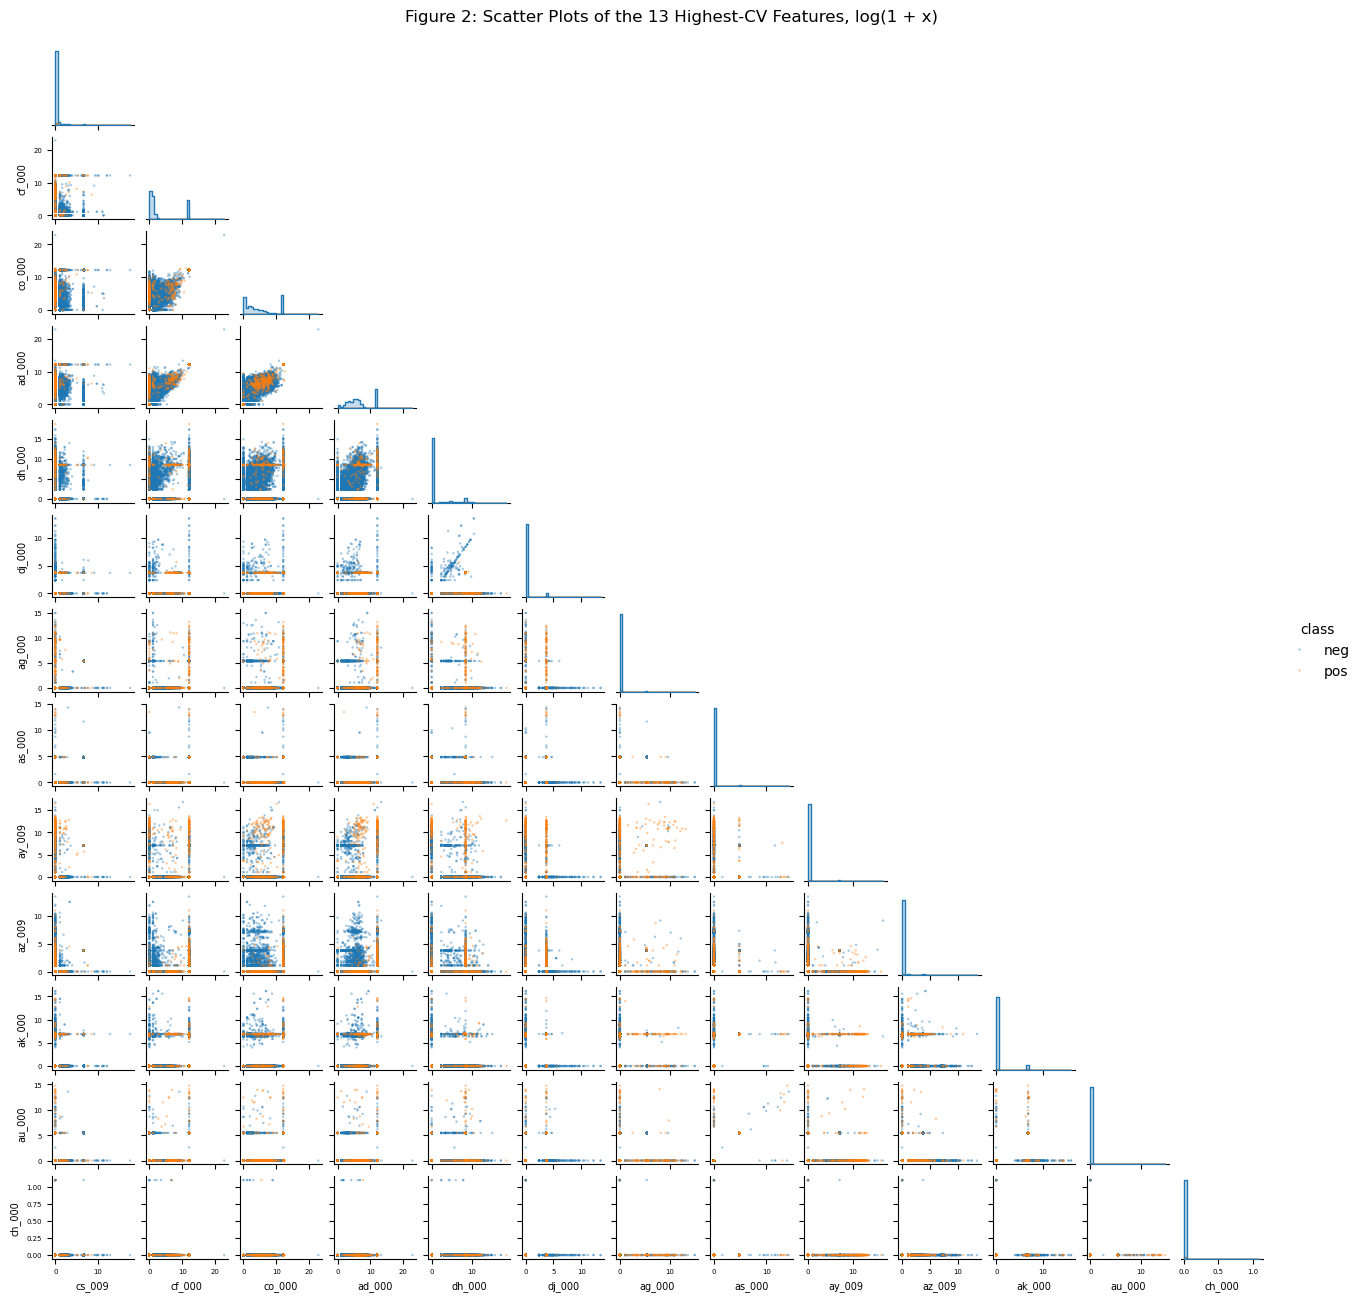

In [6]:
# Prompt: "Make a compact scatter plot matrix of those 13 features colored by class, like p. 129 of ISLR."
# Scatter plot matrix, colored by class
pair_grid = sns.pairplot(
    plot_data,
    vars=top_cv_features,
    hue="class",
    hue_order=["neg", "pos"],
    diag_kind="hist",
    corner=True,
    height=1.0,
    plot_kws={"s": 3, "alpha": 0.4, "linewidth": 0},
    diag_kws={"bins": 30, "element": "step"},
)
for ax in pair_grid.axes.flat:
    if ax is not None:
        ax.tick_params(labelsize=5)
        ax.xaxis.label.set_size(7)
        ax.yaxis.label.set_size(7)
pair_grid.figure.suptitle("Figure 2: Scatter Plots of the 13 Highest-CV Features, log(1 + x)", y=1.01)
plt.show()


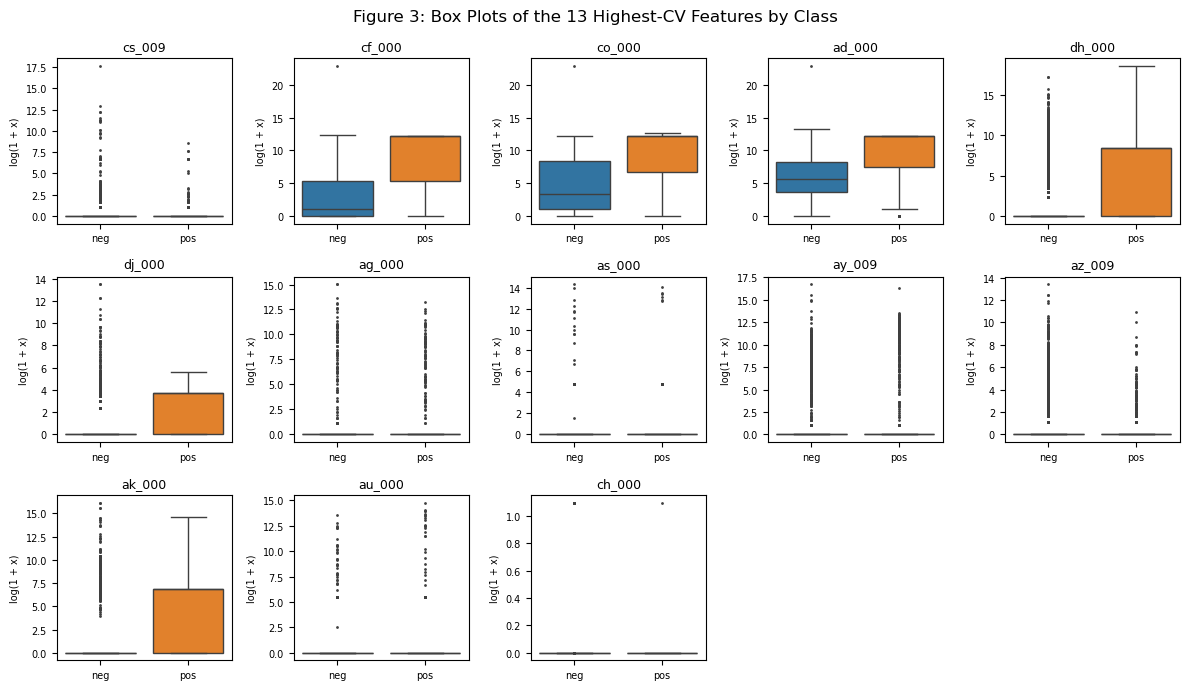

In [7]:
# Prompt: "Make small box plots of each of the 13 features split by class in one grid."
# Box plot of each feature by class
fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for ax, feature in zip(axes.flat, top_cv_features):
    sns.boxplot(data=plot_data, x="class", y=feature, hue="class", order=["neg", "pos"], fliersize=1, ax=ax)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("log(1 + x)", fontsize=7)
    ax.tick_params(labelsize=7)
for ax in axes.flat[n_top:]:
    ax.axis("off")
fig.suptitle("Figure 3: Box Plots of the 13 Highest-CV Features by Class")
fig.tight_layout()
plt.show()


You can't really make any conclusions about pure significance given just the scatterplots. Scatterplots will tell you some general correlation between values but you can't use this to get a sense of significance for the overall feature set. 

## Question 1 b) v

In [8]:
# Prompt: "Show a table of the positive and negative counts in the training and test sets with the percent positive."
# Class counts in the training and test sets
class_counts = pd.DataFrame({
    "Training": aps_train[target_name].value_counts(),
    "Test": aps_test[target_name].value_counts(),
}).T[["neg", "pos"]]
class_counts["pos %"] = (100 * class_counts["pos"] / class_counts.sum(axis=1)).round(2)
class_counts


class,neg,pos,pos %
Training,59000,1000,1.67
Test,15625,375,2.34


The data set is very imbalanced. The training set has 59,000 negative and 1,000 positive trucks, so only 1.67% are positive (a 59 to 1 ratio). The test set has 15,625 negative and 375 positive (2.34%). 

## Question 1 c)

In [9]:
# Prompt: "Train a random forest on the imputed data with no class-imbalance compensation and turn on OOB scoring."
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

# Random forest with no class weights or resampling. oob_score=True scores each row with the trees that did not see it
rf = RandomForestClassifier(n_estimators=150, oob_score=True, n_jobs=-1, random_state=1)
rf.fit(X_train, y_train);

In [10]:
# Prompt: "Write a helper that returns the confusion matrix, AUC, and misclassification rate, and show them for the training and test sets plus the OOB error in one compact table."
# Confusion matrix, AUC, and misclassification rate for one data set
def evaluate(model, X, y):
    scores = model.predict_proba(X)[:, 1]
    predicted = model.predict(X)
    matrix = pd.DataFrame(
        confusion_matrix(y, predicted),
        index=["Actual neg", "Actual pos"],
        columns=["Predicted neg", "Predicted pos"],
    )
    return {
        "scores": scores,
        "confusion": matrix,
        "AUC": roc_auc_score(y, scores),
        "Misclassification": np.mean(predicted != y),
    }


# One row per data set: the confusion matrix counts (TN, FP, FN, TP), AUC, and misclassification
def results_table(results, extra_name, extra_auc, extra_error):
    rows = {}
    for name, r in results.items():
        (tn, fp), (fn, tp) = r["confusion"].values
        rows[name] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "AUC": r["AUC"], "Misclassification": r["Misclassification"]}
    rows[extra_name] = {"AUC": extra_auc, "Misclassification": extra_error}
    table = pd.DataFrame(rows).T
    table[["TN", "FP", "FN", "TP"]] = table[["TN", "FP", "FN", "TP"]].astype("Int64")
    return table.round(4)


rf_results = {"Training": evaluate(rf, X_train, y_train), "Test": evaluate(rf, X_test, y_test)}
results_table(rf_results, "Out of bag", np.nan, 1 - rf.oob_score_)


,TN,FP,FN,TP,AUC,Misclassification
Training,59000,0,0,1000,1.0000,0.0000
Test,15609,16,103,272,0.9943,0.0074
Out of bag,<NA>,<NA>,<NA>,<NA>,NaN,0.0058


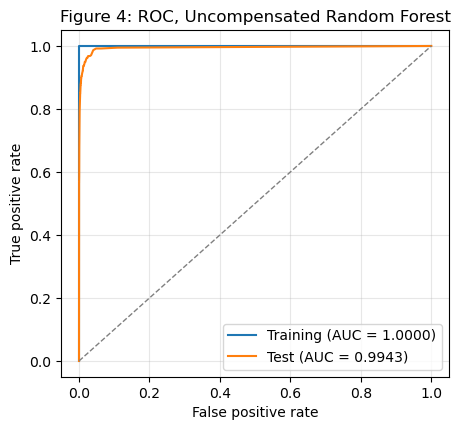

In [11]:
# Prompt: "Write a helper that plots the training and test ROC curves with their AUCs, and use it for the random forest."
# ROC curves for the training and test sets
def plot_roc(results, y_sets, title):
    fig, ax = plt.subplots(figsize=(5, 4.5))
    for name, result in results.items():
        fpr, tpr, _ = roc_curve(y_sets[name], result["scores"])
        ax.plot(fpr, tpr, label=f"{name} (AUC = {result['AUC']:.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
    plt.show()


y_sets = {"Training": y_train, "Test": y_test}
plot_roc(rf_results, y_sets, "Figure 4: ROC, Uncompensated Random Forest")


## Question 1 d)

Two common ways to handle class imbalance in random forests are:

- **Cost-Sensitive Learning (Weighted Random Forest):** give the rare class a larger weight, so misclassifying a positive costs more than misclassifying a negative. The weights are used when choosing splits and in the weighted vote at each leaf. A common choice is weights inversely proportional to class frequency, which here makes each positive count about 59 times as much as a negative.
- **Balanced Random Forest:** change the bootstrap samples instead of the cost. Each tree is grown on a sample with all, or a bootstrap of, the minority class and an equal-sized random draw from the majority class, so every tree sees balanced data. The forest still uses most of the majority data overall, because each tree draws a different subset.

I used cost-sensitive learning with `class_weight="balanced_subsample"`, which recomputes the inverse-frequency weights within each tree's bootstrap sample. Everything else matches the forest in 1 c).

In [12]:
# Prompt: "Retrain the same random forest with balanced_subsample class weights to compensate for the class imbalance."
# Same forest as 1 c), but with class weights inversely proportional to class frequency in each bootstrap sample
rf_weighted = RandomForestClassifier(
    n_estimators=150, oob_score=True, class_weight="balanced_subsample", n_jobs=-1, random_state=7
)
rf_weighted.fit(X_train, y_train);


In [13]:
# Prompt: "Show the confusion matrix counts, AUC, misclassification, and OOB error for the class-weighted forest in one table."
rf_weighted_results = {"Training": evaluate(rf_weighted, X_train, y_train), "Test": evaluate(rf_weighted, X_test, y_test)}
results_table(rf_weighted_results, "Out of bag", np.nan, 1 - rf_weighted.oob_score_)


,TN,FP,FN,TP,AUC,Misclassification
Training,59000,0,0,1000,1.000,0.0000
Test,15612,13,168,207,0.993,0.0113
Out of bag,<NA>,<NA>,<NA>,<NA>,NaN,0.0080


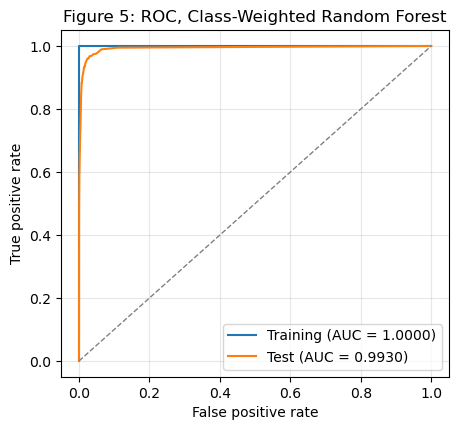

In [14]:
# Prompt: "Plot the ROC curves for the class-weighted random forest."
plot_roc(rf_weighted_results, y_sets, "Figure 5: ROC, Class-Weighted Random Forest")


In [15]:
# Prompt: "Make a side-by-side table comparing the uncompensated and class-weighted forests on the test set."
# Side-by-side comparison of 1 c) and 1 d) on the test set
def test_row(results, model):
    matrix = results["Test"]["confusion"].values
    return {
        "Test AUC": results["Test"]["AUC"],
        "Test misclassification": results["Test"]["Misclassification"],
        "OOB error": 1 - model.oob_score_,
        "False positives": matrix[0, 1],
        "False negatives": matrix[1, 0],
        "Positives caught (of 375)": matrix[1, 1],
    }


pd.DataFrame({
    "Uncompensated (1 c)": test_row(rf_results, rf),
    "Class-weighted (1 d)": test_row(rf_weighted_results, rf_weighted),
}).T.round(4)


,Test AUC,Test misclassification,OOB error,False positives,False negatives,Positives caught (of 375)
Uncompensated (1 c),0.9943,0.0074,0.0058,16.0,103.0,272.0
Class-weighted (1 d),0.9930,0.0113,0.0080,13.0,168.0,207.0


## Question 1 e)

XGBoost fits a sequence of trees to the logistic loss, so its output is a log-odds score passed through the logistic function, which is how it stands in for the logistic model at the nodes. The `reg_alpha` parameter is α, an L1 penalty on the leaf weights that shrinks small weights to exactly 0. I chose α from {0, 0.01, 0.1, 1, 10, 100} with stratified 5-fold cross-validation on the training set, keeping the other settings fixed (200 trees, learning rate 0.1, depth 6). The α with the highest mean CV AUC is used for the final model. AUC is the selection metric because the 98% majority class makes misclassification nearly flat across models. There is no compensation for class imbalance here.

In [16]:
# Prompt: "Use 5-fold stratified CV to choose the L1 penalty alpha for an XGBoost logistic model, with no class-imbalance compensation."
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier


def make_xgb(alpha):
    return XGBClassifier(
        objective="binary:logistic",
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        reg_alpha=alpha,
        tree_method="hist",
        n_jobs=-1,
        random_state=7,
    )


# 5-fold stratified CV for each alpha, scored by AUC and accuracy
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
alphas = [0, 0.01, 0.1, 1, 10, 100]

cv_rows = []
for alpha in alphas:
    scores = cross_validate(make_xgb(alpha), X_train, y_train, cv=cv5, scoring=["roc_auc", "accuracy"])
    cv_rows.append({
        "alpha": alpha,
        "CV AUC": scores["test_roc_auc"].mean(),
        "CV misclassification": 1 - scores["test_accuracy"].mean(),
    })

xgb_cv = pd.DataFrame(cv_rows)
best_xgb_alpha = xgb_cv.loc[xgb_cv["CV AUC"].idxmax(), "alpha"]
print(f"Best alpha: {best_xgb_alpha}")
xgb_cv.round(4)


Best alpha: 10.0


,alpha,CV AUC,CV misclassification
0,0.00,0.9896,0.0056
1,0.01,0.9897,0.0056
2,0.10,0.9900,0.0057
3,1.00,0.9904,0.0055
4,10.00,0.9905,0.0069
5,100.00,0.9843,0.0112


In [17]:
# Prompt: "Refit XGBoost with the best alpha and show the confusion matrix counts, AUC, and misclassification for training, test, and 5-fold CV in one table."
# Refit on the whole training set with the chosen alpha
xgb = make_xgb(best_xgb_alpha).fit(X_train, y_train)
xgb_results = {"Training": evaluate(xgb, X_train, y_train), "Test": evaluate(xgb, X_test, y_test)}

xgb_best_cv = xgb_cv.loc[xgb_cv["alpha"] == best_xgb_alpha].iloc[0]
results_table(xgb_results, "5-fold CV", xgb_best_cv["CV AUC"], xgb_best_cv["CV misclassification"])


,TN,FP,FN,TP,AUC,Misclassification
Training,58972,28,128,872,0.9981,0.0026
Test,15601,24,104,271,0.9955,0.0080
5-fold CV,<NA>,<NA>,<NA>,<NA>,0.9905,0.0069


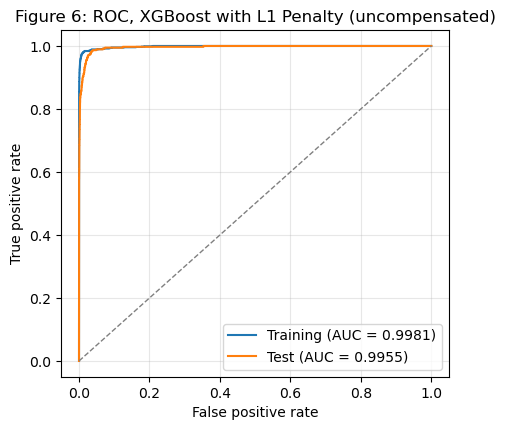

In [18]:
# Prompt: "Plot the training and test ROC curves for the XGBoost model."
plot_roc(xgb_results, y_sets, "Figure 6: ROC, XGBoost with L1 Penalty (uncompensated)")


Cross-validation picks α = 10, which has the highest CV AUC (0.9905). AUC changes very little from α = 0 to α = 10, then drops at α = 100, where the penalty is strong enough to zero out too many leaf weights. CV misclassification is lowest around α = 1 (0.55%) and rises to 0.69% at α = 10, so the AUC choice gives up a little accuracy at the default 0.5 threshold in exchange for better ranking of the trucks.

Unlike the random forest, XGBoost does not memorize the training set: training AUC is 0.9981 with 0.26% error, because boosting with shrinkage and an L1 penalty does not grow pure leaves. On the test set the AUC is 0.9955, the highest so far, and the misclassification rate is 0.80% (128 of 16,000). As with the uncompensated random forest, most errors are missed positives: 104 of 375 positive trucks (28%) are called negative, against only 24 false positives.

The 5-fold CV error of 0.69% is a little lower than the 0.80% test error, and the CV AUC (0.9905) is a little lower than the test AUC (0.9955). So CV gives a close, slightly optimistic estimate of the test error. The gap again comes partly from the test set having a higher share of positives (2.34% vs 1.67%), which is where the model makes its mistakes.

## Question 1 f)

SMOTE balances the classes by creating synthetic positives: for each real positive it picks one of its 5 nearest positive neighbors and adds a new point at a random spot on the line between them. Applied to the full training set, this adds 58,000 synthetic positives so both classes have 59,000 rows.

cross-validate is to apply SMOTE inside each fold, to the 4 training folds only, and score on the untouched held-out fold. The wrong way is to apply SMOTE to the whole training set first and then split it. Synthetic points made from a held-out positive's neighbors would then end up in the training folds, and the held-out fold would be balanced instead of 1.7% positive, so the CV error would be far too optimistic. 

In [19]:
# Prompt: "Choose alpha again with 5-fold CV, but apply SMOTE inside each fold using an imblearn pipeline so the held-out fold is never resampled."
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline


def make_smote_xgb(alpha):
    # SMOTE runs only on the data passed to fit, so in CV it only touches the training folds
    return ImbPipeline([
        ("smote", SMOTE(k_neighbors=5, random_state=7)),
        ("xgb", make_xgb(alpha)),
    ])


# Same alphas and folds as 1 e)
smote_cv_rows = []
for alpha in alphas:
    scores = cross_validate(make_smote_xgb(alpha), X_train, y_train, cv=cv5, scoring=["roc_auc", "accuracy"])
    smote_cv_rows.append({
        "alpha": alpha,
        "CV AUC": scores["test_roc_auc"].mean(),
        "CV misclassification": 1 - scores["test_accuracy"].mean(),
    })

smote_xgb_cv = pd.DataFrame(smote_cv_rows)
best_smote_alpha = smote_xgb_cv.loc[smote_xgb_cv["CV AUC"].idxmax(), "alpha"]
print(f"Best alpha: {best_smote_alpha}")
smote_xgb_cv.round(4)


Best alpha: 0.01


,alpha,CV AUC,CV misclassification
0,0.00,0.9885,0.0068
1,0.01,0.9891,0.0068
2,0.10,0.9886,0.0067
3,1.00,0.9888,0.0068
4,10.00,0.9885,0.0078
5,100.00,0.9869,0.0171


In [20]:
# Prompt: "Refit the SMOTE + XGBoost pipeline on the full training set with the best alpha and show the same table as in 1 e)."
# Refit on the whole SMOTE-balanced training set with the chosen alpha
smote_xgb = make_smote_xgb(best_smote_alpha).fit(X_train, y_train)
X_train_smote, y_train_smote = smote_xgb.named_steps["smote"].fit_resample(X_train, y_train)
print(f"Training set after SMOTE: {X_train_smote.shape[0]} rows, {y_train_smote.value_counts().to_dict()}")

# Training metrics are on the original training set, so they are comparable with 1 e)
smote_xgb_results = {"Training": evaluate(smote_xgb, X_train, y_train), "Test": evaluate(smote_xgb, X_test, y_test)}

smote_best_cv = smote_xgb_cv.loc[smote_xgb_cv["alpha"] == best_smote_alpha].iloc[0]
results_table(smote_xgb_results, "5-fold CV", smote_best_cv["CV AUC"], smote_best_cv["CV misclassification"])


Training set after SMOTE: 118000 rows, {0: 59000, 1: 59000}


,TN,FP,FN,TP,AUC,Misclassification
Training,59000,0,7,993,1.0000,0.0001
Test,15572,53,63,312,0.9941,0.0072
5-fold CV,<NA>,<NA>,<NA>,<NA>,0.9891,0.0068


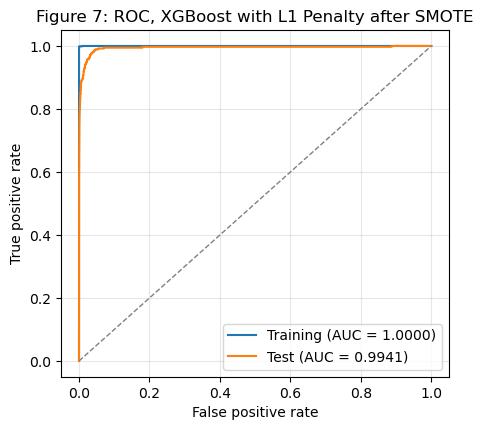

In [21]:
# Prompt: "Plot the training and test ROC curves for the SMOTE XGBoost model."
plot_roc(smote_xgb_results, y_sets, "Figure 7: ROC, XGBoost with L1 Penalty after SMOTE")


In [22]:
# Prompt: "Make a table comparing the uncompensated XGBoost from 1 e) with the SMOTE version."
# Uncompensated (1 e) vs SMOTE (1 f)
def xgb_row(results, cv_table, alpha):
    matrix = results["Test"]["confusion"].values
    cv_row = cv_table.loc[cv_table["alpha"] == alpha].iloc[0]
    return {
        "alpha": alpha,
        "CV AUC": cv_row["CV AUC"],
        "CV misclassification": cv_row["CV misclassification"],
        "Test AUC": results["Test"]["AUC"],
        "Test misclassification": results["Test"]["Misclassification"],
        "False positives": matrix[0, 1],
        "False negatives": matrix[1, 0],
        "Positives caught (of 375)": matrix[1, 1],
    }


pd.DataFrame({
    "Uncompensated (1 e)": xgb_row(xgb_results, xgb_cv, best_xgb_alpha),
    "SMOTE (1 f)": xgb_row(smote_xgb_results, smote_xgb_cv, best_smote_alpha),
}).T.round(4)


,alpha,CV AUC,CV misclassification,Test AUC,Test misclassification,False positives,False negatives,Positives caught (of 375)
Uncompensated (1 e),10.00,0.9905,0.0069,0.9955,0.0080,24.0,104.0,271.0
SMOTE (1 f),0.01,0.9891,0.0068,0.9941,0.0072,53.0,63.0,312.0


# Question 2
ISLR 6.6.3

At $s = 0$ every $\beta_j$ is forced to 0, so the model only predicts the intercept. As $s$ increases the constraint $\sum_j |\beta_j| \le s$ loosens, the model becomes more flexible, and once $s$ is large enough the lasso gives the least squares fit.

**(a) Training RSS: iv. Steadily decrease.** A larger $s$ lets the coefficients fit the training data more closely, and the minimum RSS can only go down when the constraint gets looser. It stops falling once it reaches the least squares RSS.

**(b) Test RSS: ii. Decrease initially, then eventually start increasing in a U shape.** At first, letting in the important predictors lowers the bias, so test RSS falls. After a point the extra flexibility starts fitting noise, the variance grows faster than the bias falls, and test RSS rises again.

**(c) Variance: iii. Steadily increase.** At $s = 0$ the model is a constant and has almost no variance. More flexibility makes the coefficient estimates more sensitive to the particular training sample.

**(d) Squared bias: iv. Steadily decrease.** A more flexible model can get closer to the true relationship, so the bias goes down as $s$ grows.

**(e) Irreducible error: v. Remain constant.** $\text{Var}(\epsilon)$ is the noise in the data itself and does not depend on the model or on $s$.

# Question 3
ISLR 6.6.5

With $x_{11} = x_{12} = x_1$ and $x_{21} = x_{22} = x_2$, the fitted value for observation $i$ is $\beta_1 x_i + \beta_2 x_i = (\beta_1 + \beta_2)x_i$, and $\hat\beta_0 = 0$.

**(a)** Ridge regression minimizes
$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$
which here is $(y_1 - (\beta_1 + \beta_2)x_1)^2 + (y_2 - (\beta_1 + \beta_2)x_2)^2 + \lambda(\beta_1^2 + \beta_2^2)$.

**(b)** The RSS part depends only on the sum $t = \beta_1 + \beta_2$. For a fixed $t$, the penalty is
$$\beta_1^2 + \beta_2^2 = \frac{(\beta_1 + \beta_2)^2 + (\beta_1 - \beta_2)^2}{2} = \frac{t^2}{2} + \frac{(\beta_1 - \beta_2)^2}{2},$$
which is smallest when $\beta_1 = \beta_2$. Any solution with $\beta_1 \ne \beta_2$ could be replaced by $(t/2, t/2)$, which has the same RSS and a smaller penalty, so the ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$.

**(c)** The lasso minimizes
$$(y_1 - (\beta_1 + \beta_2)x_1)^2 + (y_2 - (\beta_1 + \beta_2)x_2)^2 + \lambda(|\beta_1| + |\beta_2|).$$

**(d)** The RSS again depends only on $t = \beta_1 + \beta_2$. For a fixed $t$, $|\beta_1| + |\beta_2| \ge |\beta_1 + \beta_2| = |t|$, with equality whenever $\beta_1$ and $\beta_2$ have the same sign (or one is 0). So every pair with the same sign and the same sum has exactly the same objective value. If $\hat t$ is the optimal sum, every point on the segment $\hat\beta_1 + \hat\beta_2 = \hat t$ with $\hat\beta_1, \hat\beta_2 \ge 0$ (or both $\le 0$ if $\hat t < 0$) is a lasso solution, so the solution is not unique. Geometrically, the RSS contours are lines parallel to $\beta_1 + \beta_2 = \text{const}$, which are parallel to an edge of the lasso diamond $|\beta_1| + |\beta_2| \le s$, so they touch it along the whole edge instead of at one corner.

# Question 4
ISLR 8.4.5

**Majority vote:** 6 of the 10 estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, so 6 trees vote Red and 4 vote Green. The prediction is **Red**.

**Average probability:** the mean is $\frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.5}{10} = 0.45 < 0.5$, so the prediction is **Green**.

The two methods disagree because the four Green votes are very confident (0.1 to 0.2), which pulls the average down, while the six Red votes are only slightly above 0.5.

# Question 5
ISLR 9.7.3

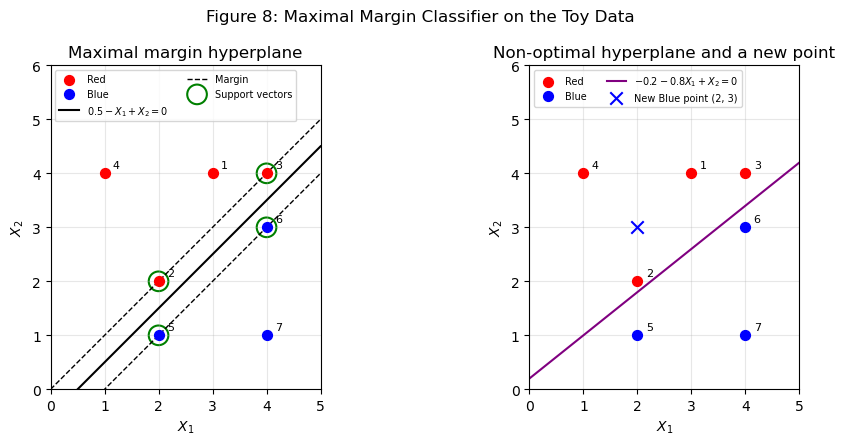

In [23]:
# Toy data from the exercise
q5_X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
q5_red = q5_X[:4]
q5_blue = q5_X[4:]
x1 = np.linspace(0, 5, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax in axes:
    ax.scatter(q5_red[:, 0], q5_red[:, 1], color="red", s=50, label="Red", zorder=3)
    ax.scatter(q5_blue[:, 0], q5_blue[:, 1], color="blue", s=50, label="Blue", zorder=3)
    for i, (a, b) in enumerate(q5_X, start=1):
        ax.annotate(str(i), (a, b), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 6)  # extra room at the top for the legend
    ax.set_aspect("equal")
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")
    ax.grid(alpha=0.3)

# (a), (b), (d), (e): maximal margin hyperplane X2 = X1 - 0.5, margins X2 = X1 and X2 = X1 - 1, support vectors circled
ax = axes[0]
ax.plot(x1, x1 - 0.5, color="black", label="$0.5 - X_1 + X_2 = 0$")
ax.plot(x1, x1, color="black", linestyle="--", linewidth=1, label="Margin")
ax.plot(x1, x1 - 1, color="black", linestyle="--", linewidth=1)
support = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(support[:, 0], support[:, 1], s=200, facecolors="none", edgecolors="green", linewidths=1.5, label="Support vectors")
ax.set_title("Maximal margin hyperplane")
ax.legend(fontsize=7, loc="upper left", ncol=2)

# (g), (h): a separating hyperplane that is not optimal, and an extra Blue point that breaks separability
ax = axes[1]
ax.plot(x1, 0.8 * x1 + 0.2, color="purple", label="$-0.2 - 0.8X_1 + X_2 = 0$")
ax.scatter([2], [3], color="blue", marker="x", s=80, label="New Blue point (2, 3)", zorder=3)
ax.set_title("Non-optimal hyperplane and a new point")
ax.legend(fontsize=7, loc="upper left", ncol=2)

fig.suptitle("Figure 8: Maximal Margin Classifier on the Toy Data")
fig.tight_layout()
plt.show()


**(a)** The seven observations are plotted in Figure 8 (numbered 1 to 7).

**(b)** The optimal separating hyperplane sits halfway between the closest Red and Blue points. Red points (2, 2) and (4, 4) lie on $X_2 = X_1$, and Blue points (2, 1) and (4, 3) lie on $X_2 = X_1 - 1$, so the hyperplane is $X_2 = X_1 - 0.5$, or $0.5 - X_1 + X_2 = 0$ (left panel).

**(c)** Classify to Red if $0.5 - X_1 + X_2 > 0$ and to Blue otherwise, so $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(d)** The margin is the band between the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$. Its width from the hyperplane to each side is $\frac{0.5}{\sqrt{2}} \approx 0.354$.

**(e)** The support vectors are observations 2 (2, 2) and 3 (4, 4) for Red, and 5 (2, 1) and 6 (4, 3) for Blue (circled in green).

**(f)** Observation 7 (4, 1) is not a support vector. It is far from the margin, at distance $\frac{|0.5 - 4 + 1|}{\sqrt{2}} \approx 1.77$ from the hyperplane. The hyperplane depends only on the support vectors, so a small move of observation 7 that keeps it outside the margin does not change it.

**(g)** $-0.2 - 0.8X_1 + X_2 = 0$ (right panel) separates the two classes, but it is not optimal because it passes closer to some points than the maximal margin hyperplane does. For example it is only 0.4 below (4, 3) vertically.

**(h)** Adding a Blue point at (2, 3) makes the classes non-separable: it lies inside the triangle formed by the Red points (1, 4), (4, 4), and (2, 2), so no straight line can put it on the Blue side without also putting a Red point there (right panel).

## References
- APS Failure at Scania Trucks data set (UCI Machine Learning Repository): https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks